# Laboratorio 13 — Modelos de Difusión
**Redes Neuronales y Aprendizaje Profundo — UNI FIIS, Unidad de Posgrado**
Aldo Camargo Fernández-Baca, Ph.D.

Acompaña a las instrucciones `Lab13_Difusion.pdf`. Usted implementará las piezas centrales de un modelo de difusión — el proceso directo, la pérdida de DDPM, los muestreadores DDPM y DDIM, y la guía sin clasificador — y las usará sobre datos 2D y sobre **Fashion-MNIST**.

| Parte | Contenido | Tiempo | Puntos |
|---|---|---|---|
| 0 | Preparación | 10 min | — |
| 1 | Proceso directo, posterior y horarios | 15 min | 3 |
| 2 | Pérdida y muestreo DDPM; 8 gaussianas | 25 min | 5 |
| 3 | DDIM sobre Fashion-MNIST: pasos vs. calidad | 30 min | 5 |
| 4 | Classifier-free guidance: fidelidad vs. diversidad | 30 min | 5 |
| 5 | Preguntas de cierre | 10 min | 2 |

**Reglas del notebook**
* Complete solo las celdas marcadas con `# TODO`. Cada función tiene una **prueba automática** debajo: no avance hasta que imprima `OK`.
* Use **GPU** (*Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*).
* Convención de índices (igual que en la clase): el índice de Python `t = 0, …, T-1` corresponde al paso $t+1$ de las notas.
* Las celdas de entrenamiento tardan ≈4 min cada una con T4. Mientras corren, Colab le deja **escribir** en otras celdas (se ejecutarán en cola): aproveche ese tiempo.

**Solución ejecutada localmente — 27 de octubre de 2026 (America/Lima).**
Python 3.12.12; PyTorch 2.11.0+cu128; torchvision 0.26.0+cu128;
CUDA 12.8; NVIDIA GeForce RTX 5090 (32 GB). Se mantuvieron T=1000, PASOS_2D=6000,
EPOCAS=5, N_FID=1000, las semillas, las redes y las pruebas originales. Los tiempos corresponden
a esta GPU, con lotes de 500 para las comparaciones. Datos y checkpoints quedan fuera de la entrega.

**Lectura de las métricas.** El clasificador auxiliar alcanzó 90.2%
en prueba. FID* usa sus características de 128 dimensiones: la referencia entre subconjuntos reales
fue 4.938, un valor empírico con variación muestral, no una cota inferior
matemática ni el FID estándar de los artículos. SciPy advirtió covarianzas singulares; se conservó
la función del docente y se verificaron valores finitos. La referencia real-vs-real se contrastó
con un cálculo espectral para matrices semidefinidas positivas: diferencia absoluta 0,000012.

**Uso de las respuestas.** Las celdas Respuesta presentan una solución explicada con números de
esta corrida. El grupo debe revisarla y redactar su versión con sus palabras, según el apartado
de honestidad académica del PDF, página 6.


## Parte 0. Preparación (10 min)

Ejecute las celdas de esta sección sin modificarlas. Definen las utilidades, los horarios, las redes de la clase (`MLPRuido`, `UNet`), el conjunto Fashion-MNIST y un **clasificador auxiliar** que usaremos para medir la calidad de las muestras con un FID simplificado (FID\*), como en la sección G8 de la Clase 11.

In [1]:
import math, time, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms as transforms
from torchvision.utils import make_grid
from scipy import linalg

torch.manual_seed(0); np.random.seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '| dispositivo:', device)
if device == 'cpu':
    print('ATENCIÓN: sin GPU las Partes 3 y 4 serán muy lentas. Cambie el tipo de entorno.')

def sincronizar():
    if device == 'cuda': torch.cuda.synchronize()

def mostrar(imgs, nrow=10, titulo='', ax=None):
    grid = make_grid(imgs.detach().cpu().float().clamp(-1, 1) * 0.5 + 0.5, nrow=nrow, padding=2, pad_value=1)
    ax = ax or plt.figure(figsize=(nrow * 0.6, (len(imgs) // nrow) * 0.6 + 0.4)).gca()
    ax.imshow(grid.permute(1, 2, 0)); ax.axis('off'); ax.set_title(titulo)

def horario_lineal(T, b1=1e-4, bT=0.02):
    return torch.linspace(b1, bT, T, dtype=torch.float64)

def horario_coseno(T, s=0.008):
    t = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((t / T + s) / (1 + s)) * math.pi / 2) ** 2
    abar = f / f[0]
    return (1 - abar[1:] / abar[:-1]).clamp(max=0.999)

def e(v, t, x):
    # toma v[t] (un valor por elemento del lote) y lo deja listo para multiplicar a x
    return v[t].view(-1, *([1] * (x.dim() - 1)))

def rapido(modelo):
    # envoltura para muestrear en media precisión en GPU (mucho más rápido en T4); devuelve float32
    def f(x, t, **kw):
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
            return modelo(x, t, **kw).float()
    return f

T = 1000

PyTorch 2.11.0+cu128 | dispositivo: cuda


In [2]:
class EmbTiempo(nn.Module):
    # embedding sinusoidal de Vaswani et al. (2017), usado por DDPM para el paso t
    def __init__(self, d):
        super().__init__(); self.d = d
    def forward(self, t):
        mitad = self.d // 2
        frec = torch.exp(-math.log(10000) * torch.arange(mitad, device=t.device) / mitad)
        ang = t.float().unsqueeze(-1) * frec
        return torch.cat([ang.sin(), ang.cos()], -1)

class MLPRuido(nn.Module):
    def __init__(self, h=128):
        super().__init__()
        self.emb = nn.Sequential(EmbTiempo(64), nn.Linear(64, h), nn.SiLU())
        self.l1, self.l2, self.l3 = nn.Linear(2, h), nn.Linear(h, h), nn.Linear(h, h)
        self.out = nn.Linear(h, 2)
    def forward(self, x, t):
        e = self.emb(t)
        h = F.silu(self.l1(x) + e)
        h = F.silu(self.l2(h) + e)
        h = F.silu(self.l3(h) + e)
        return self.out(h)

class BloqueRes(nn.Module):
    def __init__(self, c_in, c_out, d_emb, dropout=0.1):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, c_in), nn.Conv2d(c_in, c_out, 3, padding=1)
        self.emb = nn.Linear(d_emb, c_out)
        self.n2, self.c2 = nn.GroupNorm(8, c_out), nn.Conv2d(c_out, c_out, 3, padding=1)
        self.drop = nn.Dropout(dropout)
        self.salto = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()
    def forward(self, x, emb):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.emb(emb)[:, :, None, None]              # el paso t (y la clase) entra aquí
        h = self.c2(self.drop(F.silu(self.n2(h))))
        return h + self.salto(x)

class Atencion(nn.Module):
    def __init__(self, c, cabezas=4):
        super().__init__()
        self.norm, self.att = nn.GroupNorm(8, c), nn.MultiheadAttention(c, cabezas, batch_first=True)
    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x).flatten(2).transpose(1, 2)          # (B, H*W, C): cada píxel es un token
        h, _ = self.att(h, h, h)
        return x + h.transpose(1, 2).view(B, C, H, W)

class UNet(nn.Module):
    def __init__(self, c=64, n_clases=None):
        super().__init__()
        d = 4 * c
        self.emb_t = nn.Sequential(EmbTiempo(c), nn.Linear(c, d), nn.SiLU(), nn.Linear(d, d))
        self.n_clases = n_clases
        self.emb_y = nn.Embedding(n_clases + 1, d) if n_clases else None   # índice n_clases = "vacío" (D8)
        self.entrada = nn.Conv2d(1, c, 3, padding=1)
        self.e1 = BloqueRes(c, c, d);          self.baja1 = nn.Conv2d(c, c, 3, 2, 1)           # 28 -> 14
        self.e2 = BloqueRes(c, 2 * c, d);      self.baja2 = nn.Conv2d(2 * c, 2 * c, 3, 2, 1)   # 14 -> 7
        self.m1, self.att, self.m2 = BloqueRes(2 * c, 2 * c, d), Atencion(2 * c), BloqueRes(2 * c, 2 * c, d)
        self.sube2 = nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv2d(2 * c, 2 * c, 3, padding=1))  # 7 -> 14
        self.d2 = BloqueRes(4 * c, 2 * c, d)
        self.sube1 = nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv2d(2 * c, c, 3, padding=1))      # 14 -> 28
        self.d1 = BloqueRes(2 * c, c, d)
        self.salida = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv2d(c, 1, 3, padding=1))
    def forward(self, x, t, y=None):
        emb = self.emb_t(t)
        if self.emb_y is not None:
            if y is None: y = torch.full((len(x),), self.n_clases, device=x.device)
            emb = emb + self.emb_y(y)
        h0 = self.entrada(x)
        h1 = self.e1(h0, emb)                                 # 28x28
        h2 = self.e2(self.baja1(h1), emb)                     # 14x14
        h = self.m2(self.att(self.m1(self.baja2(h2), emb)), emb)   # 7x7
        h = self.d2(torch.cat([self.sube2(h), h2], 1), emb)   # 14x14
        h = self.d1(torch.cat([self.sube1(h), h1], 1), emb)   # 28x28
        return self.salida(h)

print('MLPRuido y UNet definidas (idénticas al notebook de la Clase 13).')

MLPRuido y UNet definidas (idénticas al notebook de la Clase 13).


100.0%


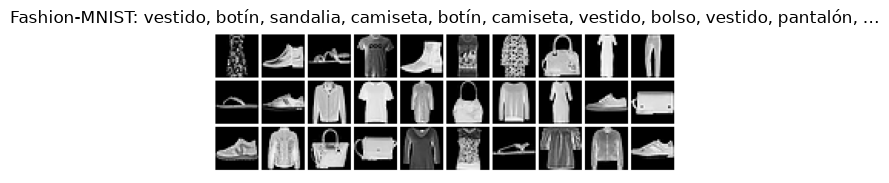

In [3]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])   # [0,1] -> [-1,1]
fm_train = torchvision.datasets.FashionMNIST('data', train=True, download=True, transform=transform)
fm_test  = torchvision.datasets.FashionMNIST('data', train=False, download=True, transform=transform)
CLASES = ['camiseta', 'pantalón', 'suéter', 'vestido', 'abrigo', 'sandalia', 'camisa', 'zapatilla', 'bolso', 'botín']
loader = torch.utils.data.DataLoader(fm_train, batch_size=128, shuffle=True, drop_last=True, num_workers=2)
x_ej, y_ej = next(iter(loader))
mostrar(x_ej[:30], titulo='Fashion-MNIST: ' + ', '.join(CLASES[i] for i in y_ej[:10].tolist()) + ', …'); plt.show()

In [4]:
# ---- Clasificador auxiliar y FID* (como en la Clase 11, G8) -------------------------------
class Clasificador(nn.Module):
    def __init__(self):
        super().__init__()
        self.caracteristicas = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU())
        self.salida = nn.Linear(128, 10)
    def forward(self, x): return self.salida(self.caracteristicas(x))

torch.manual_seed(0)
clf = Clasificador().to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
for ep in range(3):
    for x, y in loader:
        loss = F.cross_entropy(clf(x.to(device)), y.to(device))
        opt.zero_grad(); loss.backward(); opt.step()
clf.eval()
test_loader = torch.utils.data.DataLoader(fm_test, batch_size=500)
with torch.no_grad():
    acc = np.mean([(clf(x.to(device)).argmax(1).cpu() == y).float().mean().item() for x, y in test_loader])
print(f'Exactitud del clasificador auxiliar en prueba: {acc:.3f}')

@torch.no_grad()
def caracteristicas(imgs, lote=500):
    feats, clases = [], []
    for i in range(0, len(imgs), lote):
        f = clf.caracteristicas(imgs[i:i + lote].to(device).float().clamp(-1, 1))   # recorte al rango de los datos
        feats.append(f.cpu()); clases.append(clf.salida(f).argmax(1).cpu())
    return torch.cat(feats).double().numpy(), torch.cat(clases)

def fid(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    raiz = linalg.sqrtm(s1 @ s2)
    raiz = (raiz[0] if isinstance(raiz, tuple) else raiz).real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * raiz))

def diversidad_por_clase(f, clases_pedidas):
    # distancia media entre pares de características dentro de cada clase pedida, promediada sobre clases
    d = []
    for c in clases_pedidas.unique():
        fc = torch.tensor(f[(clases_pedidas == c).numpy()])
        if len(fc) > 1: d.append(torch.pdist(fc).mean().item())
    return float(np.mean(d))

N_FID = 1000
reales = torch.stack([fm_test[i][0] for i in range(N_FID)])
y_reales = torch.tensor([fm_test[i][1] for i in range(N_FID)])
f_reales, _ = caracteristicas(reales)
f_ref, _ = caracteristicas(torch.stack([fm_test[i][0] for i in range(N_FID, 2 * N_FID)]))
DIV_REAL = diversidad_por_clase(f_reales, y_reales)
print(f'FID* entre dos mitades del conjunto de prueba (piso por ruido muestral): {fid(f_reales, f_ref):.2f}')
print(f'Diversidad intra-clase de los datos reales: {DIV_REAL:.2f}')

Exactitud del clasificador auxiliar en prueba: 0.902
FID* entre dos mitades del conjunto de prueba (piso por ruido muestral): 4.94
Diversidad intra-clase de los datos reales: 15.65


C:\Users\USER\AppData\Local\Temp\ipykernel_62872\1294712157.py:36: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  raiz = linalg.sqrtm(s1 @ s2)


## Parte 1. Proceso directo, posterior y horarios (15 min, 3 pts)

La clase `Horario` ya calcula $\beta_t$, $\alpha_t=1-\beta_t$, $\bar\alpha_t$ y $\bar\alpha_{t-1}$ (con $\bar\alpha_0=1$). Usted completa tres funciones.

In [6]:
class Horario:
    def __init__(self, betas):
        self.T = len(betas)
        self.betas = betas.float().to(device)
        self.alphas = 1 - self.betas
        self.abar = torch.cumprod(self.alphas, 0)
        self.abar_prev = torch.cat([torch.ones(1, device=device), self.abar[:-1]])

h_lin, h_cos = Horario(horario_lineal(T)), Horario(horario_coseno(T))

### Tarea 1.1 — Forma cerrada (1 pt)
Implemente $\mathbf{x}_t=\sqrt{\bar\alpha_t}\,\mathbf{x}_0+\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon$ (ec. 4 de las notas). Use la función `e(v, t, x)` para que funcione con lotes de cualquier forma.

In [7]:
def q_sample(h, x0, t, eps):
    # x0, eps: (B, ...);  t: (B,) enteros en [0, T-1]
    ab = e(h.abar, t, x0)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

# ---- prueba: comparamos con aplicar el paso x_t = sqrt(1-b) x_{t-1} + sqrt(b) eps, 300 veces
torch.manual_seed(0)
x0 = torch.tensor([1.5, -0.5], device=device).repeat(200000, 1)
x = x0.clone()
for i in range(300):
    x = (1 - h_lin.betas[i]).sqrt() * x + h_lin.betas[i].sqrt() * torch.randn_like(x)
xc = q_sample(h_lin, x0, torch.full((len(x0),), 299, device=device), torch.randn_like(x0))
assert xc.shape == x0.shape, 'forma incorrecta'
assert torch.allclose(x.mean(0), xc.mean(0), atol=0.01) and torch.allclose(x.var(0), xc.var(0), atol=0.01), 'no coincide con la cadena iterada'
print('OK  media iterada', x.mean(0).cpu().numpy().round(3), ' cerrada', xc.mean(0).cpu().numpy().round(3))

OK  media iterada [ 0.946 -0.315]  cerrada [ 0.947 -0.315]


### Tarea 1.2 — Posterior (1 pt)
Implemente la media y la varianza del posterior $q(\mathbf{x}_{t-1}\mid\mathbf{x}_t,\mathbf{x}_0)$ (ec. 9 de las notas):
$$\tilde{\boldsymbol\mu}_t=\frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,\mathbf{x}_0+\frac{\sqrt{\alpha_t}\,(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\,\mathbf{x}_t,\qquad \tilde\beta_t=\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t .$$
La prueba verifica la identidad de la ec. 10, $\tilde{\boldsymbol\mu}_t=\frac{1}{\sqrt{\alpha_t}}\big(\mathbf{x}_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\boldsymbol\epsilon\big)$.

In [8]:
def posterior(h, x0, xt, t):
    # devuelve (mu_til, beta_til), ambos con la forma de xt (beta_til se puede devolver con broadcast)
    beta = e(h.betas, t, xt)
    alpha = e(h.alphas, t, xt)
    ab = e(h.abar, t, xt)
    ab_prev = e(h.abar_prev, t, xt)
    mu = ab_prev.sqrt() * beta / (1 - ab) * x0
    mu = mu + alpha.sqrt() * (1 - ab_prev) / (1 - ab) * xt
    beta_til = beta * (1 - ab_prev) / (1 - ab)
    # En el primer índice, el posterior es una masa puntual en x0.
    primero = (t == 0).view(-1, *([1] * (xt.dim() - 1)))
    return torch.where(primero, x0, mu), beta_til

# ---- prueba
torch.manual_seed(1)
x0 = torch.randn(64, 1, 28, 28, device=device); eps = torch.randn_like(x0)
t = torch.randint(1, T, (64,), device=device)
xt = q_sample(h_lin, x0, t, eps)
mu, bt = posterior(h_lin, x0, xt, t)
mu_eps = (xt - e(h_lin.betas, t, xt) / (1 - e(h_lin.abar, t, xt)).sqrt() * eps) / e(h_lin.alphas, t, xt).sqrt()
assert torch.allclose(mu, mu_eps, atol=1e-3), 'la media no satisface la ec. 10'
assert (bt <= e(h_lin.betas, t, xt) + 1e-8).all(), 'beta_til debería ser <= beta'
print('OK  máx |mu_til - mu(eps)| =', (mu - mu_eps).abs().max().item())

OK  máx |mu_til - mu(eps)| = 3.266334533691406e-05


### Tarea 1.3 — Horarios (1 pt)
Para los horarios lineal y coseno calcule: (a) el paso $t$ (en la numeración de las notas, $1..T$) donde $\mathrm{SNR}(t)=\bar\alpha_t/(1-\bar\alpha_t)$ cruza 1; (b) cuántos pasos tienen $\mathrm{SNR}(t)<10^{-2}$ (la imagen es prácticamente ruido). Grafique $\log_{10}\mathrm{SNR}$ para ambos.

lineal : SNR cruza 1 en t =  260 | pasos con SNR < 0.01: 326
coseno : SNR cruza 1 en t =  497 | pasos con SNR < 0.01: 64


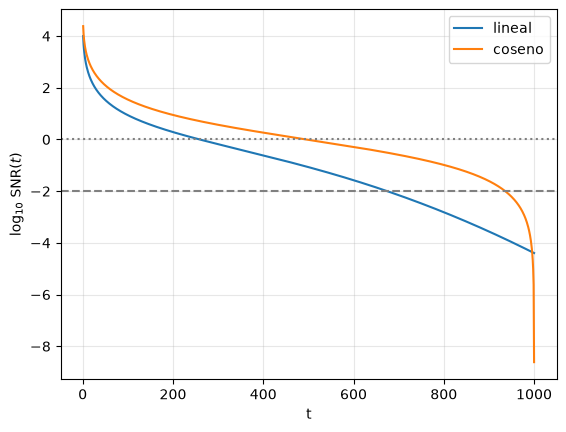

In [9]:
def analizar_horario(h):
    # devuelve (t_cruce, n_pasos_ruido): t_cruce en numeración 1..T
    snr = h.abar / (1 - h.abar)
    cruces = torch.nonzero(snr <= 1, as_tuple=False).flatten()
    t_cruce = int(cruces[0].item()) + 1 if len(cruces) else None
    return t_cruce, int((snr < 1e-2).sum().item())

for nombre, h in [('lineal', h_lin), ('coseno', h_cos)]:
    tc, nr = analizar_horario(h)
    print(f'{nombre:7s}: SNR cruza 1 en t = {tc:4d} | pasos con SNR < 0.01: {nr}')
    plt.plot(range(1, T + 1), torch.log10(h.abar / (1 - h.abar)).cpu(), label=nombre)
plt.axhline(0, color='gray', ls=':'); plt.axhline(-2, color='gray', ls='--')
plt.xlabel('t'); plt.ylabel(r'$\log_{10}\,\mathrm{SNR}(t)$'); plt.legend(); plt.grid(alpha=.3); plt.show()

**Respuesta:**

El horario lineal cruza SNR=1 en **t=260** y tiene **326 pasos (32.6 %)**
con SNR<0,01. El coseno cruza en **t=497** y tiene **64 pasos (6.4 %)**
bajo ese umbral. Todos los índices están expresados en la numeración 1…1000 de las notas.
El lineal destruye antes la señal y dedica una fracción mayor a estados casi indistinguibles de ruido;
el coseno conserva señal durante más pasos y distribuye mejor la corrupción. En este sentido,
el 32,6 % frente al 6,4 % identifica la fracción potencialmente poco informativa, sin demostrar que
esos pasos puedan eliminarse sin costo. Es consistente con el análisis de horarios de
[Nichol y Dhariwal, §3.2](https://arxiv.org/html/2102.09672v1#S3.SS2).

## Parte 2. Pérdida y muestreo DDPM sobre 8 gaussianas (25 min, 5 pts)

Usamos los mismos datos que provocaron el **colapso de modos** en la Clase 11 (G4): 8 gaussianas pequeñas en un anillo de radio 2.

In [10]:
K_MODOS, RADIO, S_MODO = 8, 2.0, 0.05
centros = torch.tensor([[RADIO * math.cos(2 * math.pi * i / K_MODOS), RADIO * math.sin(2 * math.pi * i / K_MODOS)]
                        for i in range(K_MODOS)])
def muestrear_anillo(n):
    return centros[torch.randint(0, K_MODOS, (n,))] + S_MODO * torch.randn(n, 2)

def evaluar_anillo(x):
    # (modos cubiertos con >= 2 % de las muestras dentro de 3 sigma, fracción de muestras dentro de algún modo)
    dist = torch.cdist(x.cpu(), centros)
    cerca = dist.min(1).values < 3 * S_MODO
    frac = torch.bincount(dist.argmin(1)[cerca], minlength=K_MODOS).float() / len(x)
    return int((frac > 0.02).sum()), cerca.float().mean().item()

def oraculo_gaussiano(h, m, s):
    # epsilon EXACTO para datos x0 ~ N(m, s^2 I): q(x_t) = N(sqrt(abar) m, (abar s^2 + 1 - abar) I)
    def eps(x, t, **kw):
        ab = e(h.abar, t, x)
        return (1 - ab).sqrt() * (x - ab.sqrt() * m) / (ab * s ** 2 + 1 - ab)
    return eps

### Tarea 2.1 — La pérdida simple (1 pt)
Implemente el **Algoritmo 1** (ec. 16): muestree $t\sim\mathcal U\{0,\dots,T-1\}$ y $\boldsymbol\epsilon\sim\mathcal N(\mathbf 0,\mathbf I)$ por ejemplo del lote, forme $\mathbf{x}_t$ con `q_sample` y devuelva el error cuadrático medio entre $\boldsymbol\epsilon$ y `modelo(x_t, t, **kw)`. Los `**kw` (la etiqueta `y`) se usarán en la Parte 4.

In [11]:
def perdida_simple(modelo, h, x0, **kw):
    t = torch.randint(0, h.T, (len(x0),), device=x0.device)
    eps = torch.randn_like(x0)
    xt = q_sample(h, x0, t, eps)
    return F.mse_loss(modelo(xt, t, **kw), eps)

# ---- prueba: con un modelo que siempre predice 0, la pérdida debe ser E[eps^2] = 1
cero = lambda x, t, **kw: torch.zeros_like(x)
l0 = perdida_simple(cero, h_lin, torch.randn(4096, 2, device=device))
assert abs(l0.item() - 1) < 0.05, f'esperaba ~1, obtuve {l0.item():.3f}'
# ---- con el oráculo exacto (el mejor modelo posible) la pérdida NO es cero: alcanza el mínimo teórico
#      E||eps - E[eps|x_t]||^2 / d = promedio_t  abar s^2 / (abar s^2 + 1 - abar)
m0 = torch.tensor([2.0, -1.0], device=device)
torch.manual_seed(0)
l1 = torch.stack([perdida_simple(oraculo_gaussiano(h_lin, m0, 0.5), h_lin, m0 + 0.5 * torch.randn(4096, 2, device=device))
                  for _ in range(20)]).mean()
minimo = (h_lin.abar * 0.25 / (h_lin.abar * 0.25 + 1 - h_lin.abar)).mean()
assert abs(l1.item() - minimo.item()) < 0.01, f'con el oráculo esperaba {minimo.item():.3f}, obtuve {l1.item():.3f}'
print(f'OK  modelo cero: {l0.item():.3f}   oráculo: {l1.item():.3f}   mínimo teórico: {minimo.item():.3f}')

OK  modelo cero: 1.009   oráculo: 0.172   mínimo teórico: 0.173

### Tarea 2.2 — Muestreo DDPM (1.5 pts)
Implemente el **Algoritmo 2**: desde $\mathbf{x}_T\sim\mathcal N(\mathbf 0,\mathbf I)$ (o `xT` si se da), para $t=T-1,\dots,0$:
$$\mathbf{x}_{t-1}=\frac{1}{\sqrt{\alpha_t}}\Big(\mathbf{x}_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\boldsymbol\epsilon_\theta(\mathbf{x}_t,t)\Big)+\sigma_t\mathbf z,$$
sin ruido en el último paso. Con `sigma='beta'` use $\sigma_t^2=\beta_t$; con `sigma='btil'` use $\sigma_t^2=\tilde\beta_t$ (puede reutilizar `posterior` o calcularlo directamente). Recuerde que `t` que recibe el modelo es un **tensor** de tamaño $B$.

La prueba usa el oráculo exacto para datos $\mathcal N(\mathbf m, 0.5^2\mathbf I)$: si su muestreador es correcto, las muestras deben tener esa media y esa desviación.

In [12]:
@torch.no_grad()
def muestrear_ddpm(modelo, h, forma, sigma='beta', xT=None, **kw):
    if sigma not in ('beta', 'btil'):
        raise ValueError("sigma debe ser 'beta' o 'btil'")
    x = torch.randn(forma, device=device) if xT is None else xT.clone()
    varianzas = h.betas if sigma == 'beta' else h.betas * (1 - h.abar_prev) / (1 - h.abar)
    for i in range(h.T - 1, -1, -1):
        t = torch.full((len(x),), i, device=x.device, dtype=torch.long)
        eps = modelo(x, t, **kw)
        mu = (x - h.betas[i] / (1 - h.abar[i]).sqrt() * eps) / h.alphas[i].sqrt()
        x = mu + varianzas[i].sqrt() * torch.randn_like(x) if i > 0 else mu
    return x

# ---- prueba con el oráculo gaussiano
torch.manual_seed(2)
for sg in ['beta', 'btil']:
    xs = muestrear_ddpm(oraculo_gaussiano(h_lin, m0, 0.5), h_lin, (20000, 2), sigma=sg)
    print(f'sigma={sg:4s}: media {xs.mean(0).cpu().numpy().round(3)}  desv. {xs.std(0).cpu().numpy().round(3)}   (esperado [2, -1] y 0.5)')
    assert torch.allclose(xs.mean(0), m0, atol=0.03) and torch.allclose(xs.std(0), torch.tensor(0.5, device=device), atol=0.03)
print('OK')

sigma=beta: media [ 2.001 -1.002]  desv. [0.5 0.5]   (esperado [2, -1] y 0.5)


sigma=btil: media [ 2.004 -0.999]  desv. [0.5   0.496]   (esperado [2, -1] y 0.5)
OK


### Tarea 2.3 — ¿Colapsa un modelo de difusión? (1.5 pts)
La celda entrena `MLPRuido` con **su** pérdida sobre el anillo de 8 gaussianas (≈1 min) y muestrea 3000 puntos con **su** muestreador. Complete la figura: datos en gris, muestras en color, y en el título los modos cubiertos y la fracción de muestras dentro de algún modo.

entrenado en 8s, pérdida final 0.217


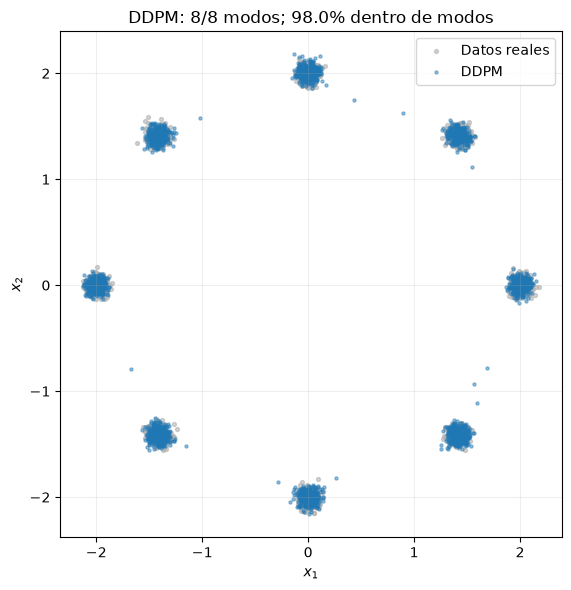

In [13]:
torch.manual_seed(0)
mlp_anillo = MLPRuido().to(device)
opt = torch.optim.Adam(mlp_anillo.parameters(), lr=2e-3)
PASOS_2D = 6000
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, PASOS_2D)
t0 = time.time()
for paso in range(PASOS_2D):
    loss = perdida_simple(mlp_anillo, h_lin, muestrear_anillo(1024).to(device))
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
print(f'entrenado en {time.time()-t0:.0f}s, pérdida final {loss.item():.3f}')

torch.manual_seed(3)
x_beta = muestrear_ddpm(mlp_anillo, h_lin, (3000, 2), sigma='beta').cpu()
real = muestrear_anillo(3000)
modos_beta, fraccion_beta = evaluar_anillo(x_beta)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(real[:, 0], real[:, 1], s=8, color='0.7', alpha=0.6, label='Datos reales')
ax.scatter(x_beta[:, 0], x_beta[:, 1], s=5, color='tab:blue', alpha=0.45, label='DDPM')
ax.set(xlabel='$x_1$', ylabel='$x_2$', aspect='equal',
       title=f'DDPM: {modos_beta}/8 modos; {fraccion_beta:.1%} dentro de modos')
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()


**Respuesta:**

La corrida DDPM cubrió **8/8 modos**, con **98.03%** de las 3000 muestras
a menos de 3σ de algún centro. No se observó colapso bajo el criterio del laboratorio; esto no es
una garantía para cualquier entrenamiento. La pérdida final del MLP fue **0,217**.

La difusión aprende a predecir ruido mediante regresión sobre ejemplos de todos los modos y niveles
de corrupción. La GAN depende del equilibrio entre generador y discriminador: concentrarse en pocos
modos puede resultar favorable transitoriamente para su objetivo adversario. El PDF (p. 3) describe
la GAN desincronizada de G4 concentrada en uno o dos modos; esa comparación proviene del docente,
no de una nueva ejecución de esa GAN. El objetivo de difusión se desarrolla en
[Ho et al., §3.4](https://arxiv.org/html/2006.11239v2#S3.SS4).

### Tarea 2.4 — $\sigma_t^2=\beta_t$ vs. $\sigma_t^2=\tilde\beta_t$ (1 pt)
Muestree el mismo modelo con `sigma='btil'` (misma semilla) y compare modos cubiertos, fracción en modos y la **desviación estándar de las muestras alrededor de su centro más cercano** (compárela con `S_MODO = 0.05`). ¿Coincide con lo que dicen Ho et al. (“resultados similares”)? ¿Cuál deja las muestras más dispersas y por qué ($\tilde\beta_t$ vs. $\beta_t$)?

Método           Modos    Dentro    sigma x    sigma y      Media
Datos reales         8   99.000%     0.0498     0.0493     0.0496
DDPM beta            8   98.033%     0.0547     0.0554     0.0550
DDPM btil            8   98.667%     0.0522     0.0512     0.0517


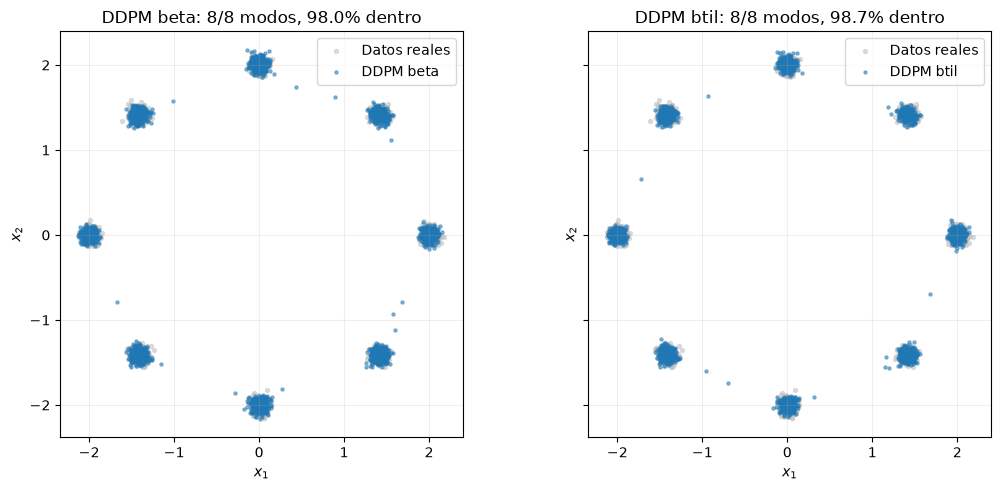

In [15]:
torch.manual_seed(3)
x_btil = muestrear_ddpm(mlp_anillo, h_lin, (3000, 2), sigma='btil').cpu()
res_anillo = []
for nombre, puntos in [('Datos reales', real), ('DDPM beta', x_beta), ('DDPM btil', x_btil)]:
    modos, fraccion = evaluar_anillo(puntos)
    cercanos = torch.cdist(puntos, centros).argmin(1)
    residuos = puntos - centros[cercanos]
    desv = residuos.std(dim=0)
    res_anillo.append(dict(metodo=nombre, modos=modos, fraccion=fraccion,
                           std_x=desv[0].item(), std_y=desv[1].item(), std_media=desv.mean().item()))
print(f'{"Método":15s} {"Modos":>6s} {"Dentro":>9s} {"sigma x":>10s} {"sigma y":>10s} {"Media":>10s}')
for r in res_anillo:
    print(f'{r["metodo"]:15s} {r["modos"]:6d} {r["fraccion"]:9.3%} '
          f'{r["std_x"]:10.4f} {r["std_y"]:10.4f} {r["std_media"]:10.4f}')
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, puntos, r in zip(axes, [x_beta, x_btil], res_anillo[1:]):
    ax.scatter(real[:, 0], real[:, 1], color='0.75', s=8, alpha=0.5, label='Datos reales')
    ax.scatter(puntos[:, 0], puntos[:, 1], s=5, alpha=0.5, label=r['metodo'])
    ax.set(xlabel='$x_1$', ylabel='$x_2$', aspect='equal',
           title=f'{r["metodo"]}: {r["modos"]}/8 modos, {r["fraccion"]:.1%} dentro')
    ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()


**Respuesta:**

Con la misma semilla, β y β̃ cubren **8/8** y **8/8** modos; sus fracciones
dentro de los modos son **98.03%** y **98.67%**.
La desviación residual media por coordenada es **0.0550** con β y
**0.0517** con β̃; los datos reales dieron **0.0496**, frente al 0,05 teórico.
Se restó a cada punto su centro más cercano y se promediaron las desviaciones de x e y;
no se usó la desviación radial, que tiene otra referencia.

Los resultados son similares en cobertura, aunque β deja muestras algo más dispersas:
β̃=β(1−ᾱ_prev)/(1−ᾱ)≤β inyecta menos ruido en cada transición. Aquí β̃ queda más cerca
de la dispersión real. Esto concuerda cualitativamente con
[Ho et al., §3.2](https://arxiv.org/html/2006.11239v2#S3.SS2), sin implicar igualdad exacta entre ambas opciones.

## Parte 3. DDIM sobre Fashion-MNIST (30 min, 5 pts)

**Primero lance la celda de entrenamiento** (≈4 min con T4). Mientras corre, escriba `muestrear_ddim` en la celda siguiente.

In [16]:
def entrenar(modelo, h, epocas, lr=2e-4, cond=False, p_vacio=0.1, ema_decay=0.999):
    # Algoritmo 1 con SU perdida_simple, precisión mixta y EMA de los pesos (devuelve el modelo EMA)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    escala = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))
    ema = copy.deepcopy(modelo).eval()
    for p in ema.parameters(): p.requires_grad_(False)
    for ep in range(1, epocas + 1):
        t0, perdidas = time.time(), []
        modelo.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            kw = {'y': reemplazar_por_vacio(y, p_vacio, modelo.n_clases)} if cond else {}
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
                loss = perdida_simple(modelo, h, x, **kw)
            opt.zero_grad(); escala.scale(loss).backward()
            escala.unscale_(opt); nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            escala.step(opt); escala.update()
            with torch.no_grad():
                for pe, pm in zip(ema.parameters(), modelo.parameters()):
                    pe.mul_(ema_decay).add_(pm, alpha=1 - ema_decay)
            perdidas.append(loss.item())
        print(f'época {ep}/{epocas} | L_simple {np.mean(perdidas):.4f} | {time.time()-t0:.0f}s')
    return ema

EPOCAS = 5
torch.manual_seed(0)
unet = UNet().to(device)
unet_ema = entrenar(unet, h_lin, EPOCAS)

época 1/5 | L_simple 0.0849 | 10s


época 2/5 | L_simple 0.0517 | 9s


época 3/5 | L_simple 0.0476 | 9s


época 4/5 | L_simple 0.0453 | 10s


época 5/5 | L_simple 0.0439 | 10s


### Tarea 3.1 — DDIM (1.5 pts)
Implemente la ec. 26 de las notas sobre la subsecuencia `seq` de `pasos` índices (ya calculada, de $T-1$ a $0$):
$$\hat{\mathbf{x}}_0=\frac{\mathbf{x}_t-\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon_\theta}{\sqrt{\bar\alpha_t}},\qquad
\mathbf{x}_{\text{prev}}=\sqrt{\bar\alpha_{\text{prev}}}\,\hat{\mathbf{x}}_0+\sqrt{1-\bar\alpha_{\text{prev}}-\sigma_t^2}\;\boldsymbol\epsilon_\theta+\sigma_t\mathbf z,\qquad
\sigma_t=\eta\sqrt{\tfrac{1-\bar\alpha_{\text{prev}}}{1-\bar\alpha_t}}\sqrt{1-\tfrac{\bar\alpha_t}{\bar\alpha_{\text{prev}}}},$$
donde “prev” es el **siguiente índice de la subsecuencia** y, después del último, $\bar\alpha_{\text{prev}}=1$.

In [18]:
@torch.no_grad()
def muestrear_ddim(modelo, h, forma, pasos=50, eta=0.0, xT=None, **kw):
    seq = torch.linspace(h.T - 1, 0, pasos).round().long().tolist()
    x = torch.randn(forma, device=device) if xT is None else xT.clone()
    if not 1 <= pasos <= h.T:
        raise ValueError('pasos debe estar entre 1 y T')
    if not 0 <= eta <= 1:
        raise ValueError('eta debe estar entre 0 y 1')
    for j, i in enumerate(seq):
        t = torch.full((len(x),), i, device=x.device, dtype=torch.long)
        ab = h.abar[i]
        ab_prev = h.abar[seq[j + 1]] if j + 1 < len(seq) else torch.ones_like(ab)
        eps = modelo(x, t, **kw)
        x0_est = (x - (1 - ab).sqrt() * eps) / ab.sqrt()
        var = (eta ** 2 * (1 - ab_prev) / (1 - ab) * (1 - ab / ab_prev)).clamp_min(0)
        direccion = (1 - ab_prev - var).clamp_min(0).sqrt() * eps
        x = ab_prev.sqrt() * x0_est + direccion
        if eta > 0 and j + 1 < len(seq):
            x = x + var.sqrt() * torch.randn_like(x)
    return x

# ---- pruebas: con el oráculo y S = T = 1000 pasos debe recuperar N(m, 0.5^2) con eta = 0 y eta = 1
torch.manual_seed(4)
for eta in [0.0, 1.0]:
    xs = muestrear_ddim(oraculo_gaussiano(h_lin, m0, 0.5), h_lin, (20000, 2), pasos=1000, eta=eta)
    print(f'S=1000, eta={eta}: media {xs.mean(0).cpu().numpy().round(3)}  desv. {xs.std(0).cpu().numpy().round(3)}')
    assert torch.allclose(xs.mean(0), m0, atol=0.03) and torch.allclose(xs.std(0), torch.tensor(0.5, device=device), atol=0.03)
# ---- con pocos pasos la media se mantiene, pero la desviación se ENCOGE (error de discretización): obsérvelo
for S_ in [100, 50, 20]:
    for eta in [0.0, 1.0]:
        xs = muestrear_ddim(oraculo_gaussiano(h_lin, m0, 0.5), h_lin, (20000, 2), pasos=S_, eta=eta)
        print(f'S={S_:4d}, eta={eta}: media {xs.mean(0).cpu().numpy().round(3)}  desv. {xs.std(0).mean().item():.3f}')
        assert torch.allclose(xs.mean(0), m0, atol=0.05) and 0.3 < xs.std(0).mean().item() < 0.52
xT = torch.randn(5, 2, device=device)
a = muestrear_ddim(oraculo_gaussiano(h_lin, m0, 0.5), h_lin, (5, 2), pasos=20, xT=xT)
b = muestrear_ddim(oraculo_gaussiano(h_lin, m0, 0.5), h_lin, (5, 2), pasos=20, xT=xT)
assert torch.equal(a, b), 'con eta=0 el muestreo debe ser determinista'
print('OK')

S=1000, eta=0.0: media [ 1.998 -0.995]  desv. [0.5 0.5]


S=1000, eta=1.0: media [ 1.996 -1.001]  desv. [0.498 0.503]
S= 100, eta=0.0: media [ 2.    -0.995]  desv. 0.486
S= 100, eta=1.0: media [ 2.    -1.001]  desv. 0.468
S=  50, eta=0.0: media [ 1.997 -0.996]  desv. 0.473
S=  50, eta=1.0: media [ 1.999 -1.001]  desv. 0.446
S=  20, eta=0.0: media [ 1.992 -0.997]  desv. 0.431
S=  20, eta=1.0: media [ 2.001 -0.998]  desv. 0.388
OK


**Observe** la salida de la prueba: incluso con el ruido **exacto**, con pocos pasos la desviación de las muestras queda por debajo de 0.5, y más con $\eta=1$. Es error de discretización, no de la red: los pasos grandes “tiran” las muestras hacia $\hat{\mathbf{x}}_0$, que es una predicción promedio. En imágenes esto se ve como muestras más suaves y menos variadas. Úselo en el análisis de la Tarea 3.2.

### Tarea 3.2 — Pasos vs. calidad vs. tiempo (2 pts)
Con el modelo EMA (`rapido(unet_ema)`), genere `N_FID = 1000` imágenes con cada configuración de la tabla, mida el tiempo de muestreo y el FID\* contra `f_reales`. Complete la lista `filas` y muestre: (a) la tabla, (b) una figura de FID\* vs. número de evaluaciones de la red (eje $x$ logarítmico), (c) 20 muestras de cada configuración. **Use la misma semilla** antes de cada configuración. Copie la tabla en su informe (Tabla 1 de las instrucciones).

*Tiempo esperado con T4: ≈3 min para DDPM con 1000 pasos; segundos para el resto.*

DDPM σ²=β, 1000 pasos: 19.28 s; FID* = 107.504


DDIM η=0, 10 pasos: 0.20 s; FID* = 438.501


C:\Users\USER\AppData\Local\Temp\ipykernel_62872\1294712157.py:36: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  raiz = linalg.sqrtm(s1 @ s2)


DDIM η=0, 25 pasos: 0.48 s; FID* = 277.931


DDIM η=0, 50 pasos: 0.97 s; FID* = 242.890


DDIM η=0, 100 pasos: 1.94 s; FID* = 218.109


DDIM η=1, 50 pasos: 0.97 s; FID* = 137.737



Tabla 1. Mismo modelo EMA; N = 1000; tiempo de muestreo sin extracción de características.
Muestreador        Pasos/NFE   Tiempo (s)       FID*   Aceleración
Real vs. real              —            —      4.938             —
DDPM σ²=β               1000        19.28    107.504         1.00x
DDIM η=0                  10         0.20    438.501        98.83x
DDIM η=0                  25         0.48    277.931        39.87x
DDIM η=0                  50         0.97    242.890        19.83x
DDIM η=0                 100         1.94    218.109         9.95x
DDIM η=1                  50         0.97    137.737        19.92x


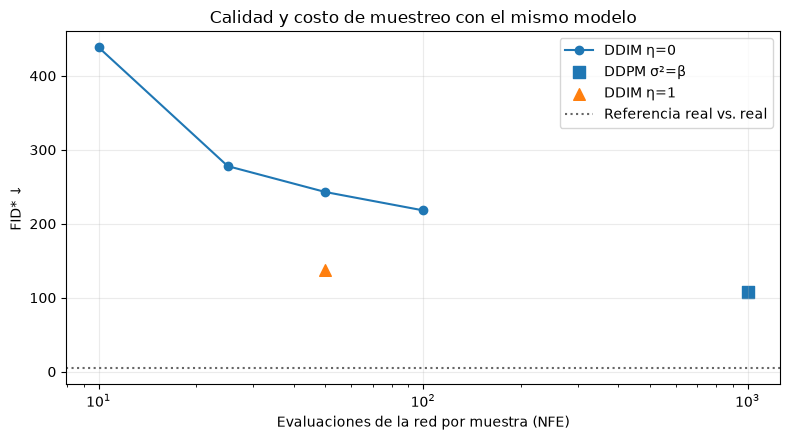

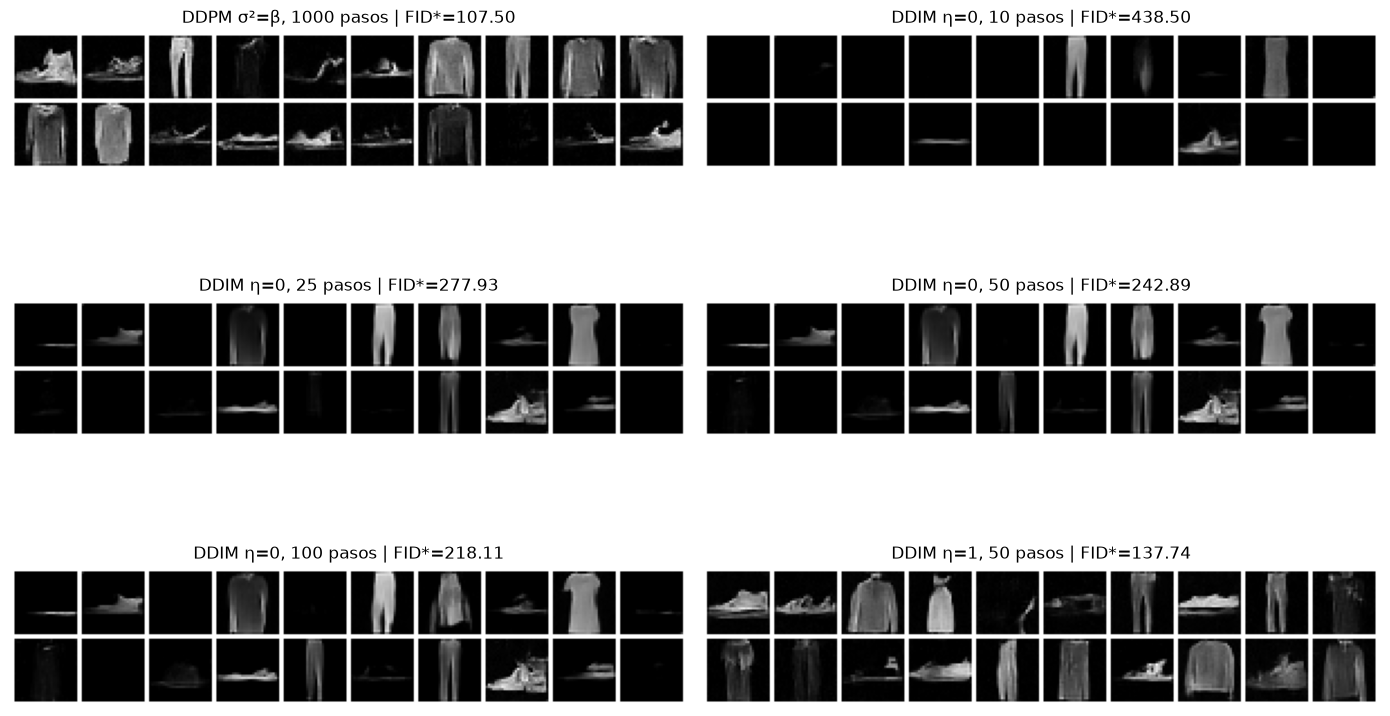

In [19]:
modelo_u = rapido(unet_ema)
configs = [('DDPM σ²=β', 1000, None), ('DDIM η=0', 10, 0.0), ('DDIM η=0', 25, 0.0), ('DDIM η=0', 50, 0.0),
           ('DDIM η=0', 100, 0.0), ('DDIM η=1', 50, 1.0)]

def generar(f, n=N_FID, lote=500):
    # llama a f(n_lote) por lotes y concatena (para no agotar la memoria)
    return torch.cat([f(min(lote, n - i)).cpu() for i in range(0, n, lote)])

filas, muestras = [], {}
for nombre, S_, eta in configs:
    torch.manual_seed(0)
    sincronizar(); inicio = time.perf_counter()
    if eta is None:
        x = generar(lambda b: muestrear_ddpm(modelo_u, h_lin, (b, 1, 28, 28), sigma='beta'))
    else:
        x = generar(lambda b: muestrear_ddim(modelo_u, h_lin, (b, 1, 28, 28), pasos=S_, eta=eta))
    sincronizar(); segundos = time.perf_counter() - inicio
    f, _ = caracteristicas(x)
    valor_fid = fid(f_reales, f)
    filas.append((nombre, S_, segundos, valor_fid))
    muestras[(nombre, S_)] = x[:20].clone()
    print(f'{nombre}, {S_} pasos: {segundos:.2f} s; FID* = {valor_fid:.3f}', flush=True)

fid_referencia = fid(f_reales, f_ref)
tiempo_ddpm = filas[0][2]
print('\nTabla 1. Mismo modelo EMA; N = 1000; tiempo de muestreo sin extracción de características.')
print(f'{"Muestreador":17s} {"Pasos/NFE":>10s} {"Tiempo (s)":>12s} {"FID*":>10s} {"Aceleración":>13s}')
print(f'{"Real vs. real":17s} {"—":>10s} {"—":>12s} {fid_referencia:10.3f} {"—":>13s}')
for nombre, S_, segundos, valor_fid in filas:
    print(f'{nombre:17s} {S_:10d} {segundos:12.2f} {valor_fid:10.3f} {tiempo_ddpm / segundos:12.2f}x')

fig, ax = plt.subplots(figsize=(8, 4.5))
ddim0 = [r for r in filas if r[0] == 'DDIM η=0']
ax.plot([r[1] for r in ddim0], [r[3] for r in ddim0], 'o-', label='DDIM η=0')
for r, marcador in [(filas[0], 's'), (filas[-1], '^')]:
    ax.scatter(r[1], r[3], marker=marcador, s=70, label=r[0])
ax.axhline(fid_referencia, ls=':', color='0.4', label='Referencia real vs. real')
ax.set(xscale='log', xlabel='Evaluaciones de la red por muestra (NFE)', ylabel='FID* ↓',
       title='Calidad y costo de muestreo con el mismo modelo')
ax.legend(); ax.grid(alpha=0.25); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(3, 2, figsize=(14, 9))
for ax, (nombre, S_, segundos, valor_fid) in zip(axes.flat, filas):
    mostrar(muestras[(nombre, S_)], nrow=10, ax=ax,
            titulo=f'{nombre}, {S_} pasos | FID*={valor_fid:.2f}')
plt.tight_layout(); plt.show()


**Respuesta:**

| Muestreador | Pasos / NFE | Tiempo (s) | FID* ↓ | Aceleración |
|---|---:|---:|---:|---:|
| Real vs. real | — | — | 4.938 | — |
| DDPM σ²=β | 1000 | 19.28 | 107.504 | 1.00× |
| DDIM η=0 | 10 | 0.20 | 438.501 | 98.83× |
| DDIM η=0 | 25 | 0.48 | 277.931 | 39.87× |
| DDIM η=0 | 50 | 0.97 | 242.890 | 19.83× |
| DDIM η=0 | 100 | 1.94 | 218.109 | 9.95× |
| DDIM η=1 | 50 | 0.97 | 137.737 | 19.92× |

Ningún DDIM η=0 probado alcanza el FID* de DDPM; el más cercano usa **100 pasos** (218.109 frente a 107.504). DDIM η=0 con 50 pasos tarda **0.97 s** por 1000 imágenes y acelera
**19.83×** frente a DDPM. El cronómetro incluye generación y traslado de muestras
a CPU, con sincronización de CUDA; excluye el clasificador y el cálculo de FID*.

En esta corrida η=1 no empeora el FID* a 50 pasos: **137.737** frente a **242.890** con η=0.
En la prueba del oráculo, la desviación a 50 pasos baja a **0,473** con η=0 y a **0,446** con η=1,
frente a 0,5: los saltos grandes acumulan error de discretización incluso con un predictor exacto.
Eso explica una posible pérdida de variación, sin aislar todos los errores de la U-Net.
El resultado del oráculo no obliga a que η=1 tenga peor FID* en imágenes: aquí interviene un predictor
aproximado entrenado solo cinco épocas. Visualmente, η=0 produce numerosas muestras casi negras;
η=1 conserva más prendas reconocibles. No se fuerza la tendencia anticipada por el enunciado.
La posibilidad de acelerar con menos pasos sin reentrenar concuerda con
[Song, Meng y Ermon](https://arxiv.org/abs/2010.02502); las cifras del artículo usan otros datos y protocolos.

### Tarea 3.3 — Determinismo e interpolación (1.5 pts)
(a) Genere dos veces con DDIM ($\eta=0$, 50 pasos) desde el mismo `xT` y verifique que las imágenes son idénticas; repita con DDPM y muestre la diferencia máxima.
(b) Implemente la **interpolación esférica** `slerp(z1, z2, lam)` (los ruidos gaussianos en alta dimensión viven cerca de una esfera de radio $\sqrt d$; la interpolación lineal pasa por el interior, donde casi no hay ruido “típico”):
$$\mathrm{slerp}(\mathbf z_1,\mathbf z_2,\lambda)=\frac{\sin((1-\lambda)\theta)}{\sin\theta}\mathbf z_1+\frac{\sin(\lambda\theta)}{\sin\theta}\mathbf z_2,\qquad \cos\theta=\frac{\mathbf z_1\cdot\mathbf z_2}{\|\mathbf z_1\|\,\|\mathbf z_2\|}.$$
Genere 4 filas de 10 imágenes interpolando entre pares de ruidos, y una fila con interpolación **lineal** para comparar. Compare también la norma de los ruidos interpolados con $\sqrt{784}=28$.

OK  mismo xT: diferencia máxima DDIM = 0; DDPM = 1.964846


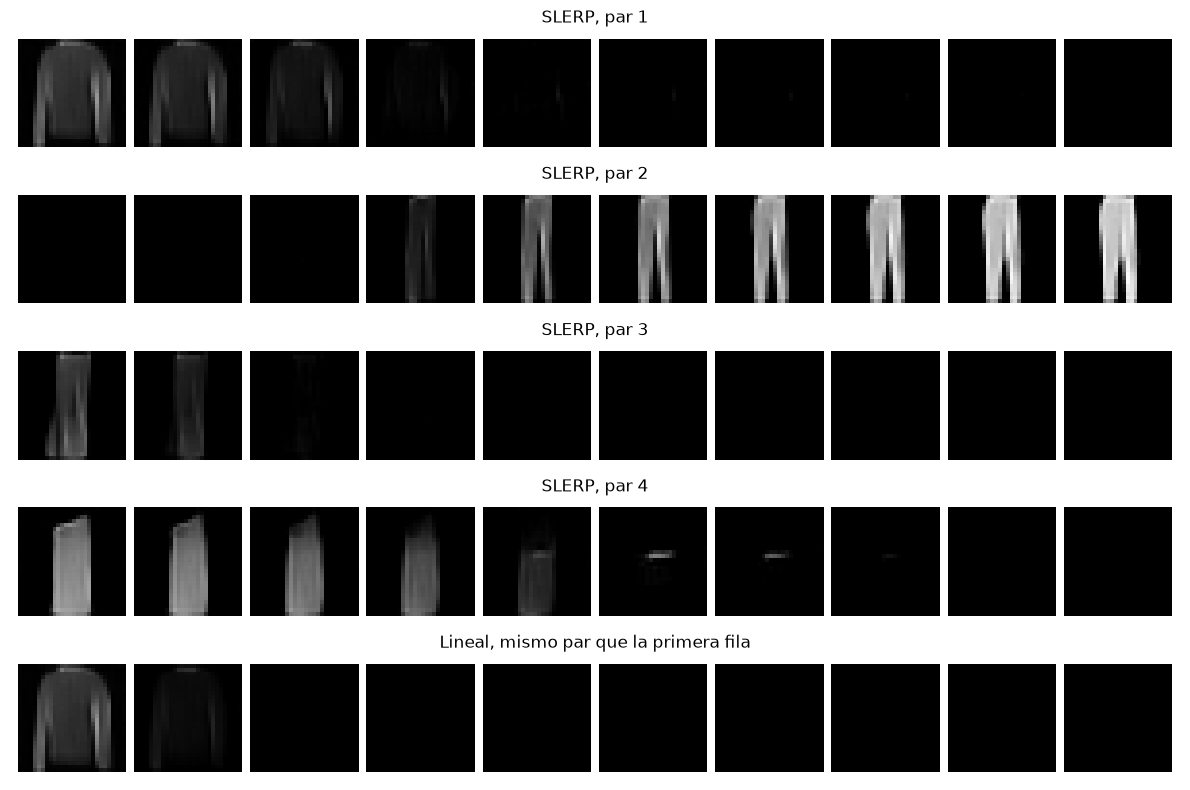

Normas SLERP (filas = pares; columnas = lambda):
[[27.35 27.37 27.45 27.57 27.72 27.88 28.03 28.15 28.23 28.26]
 [26.69 26.73 26.88 27.1  27.37 27.65 27.92 28.13 28.26 28.31]
 [27.9  27.89 27.88 27.87 27.85 27.83 27.81 27.79 27.78 27.78]
 [27.95 27.97 28.01 28.07 28.15 28.23 28.3  28.37 28.41 28.42]]
Normas lineales, par 1: [27.35 24.46 22.08 20.38 19.55 19.69 20.79 22.7  25.25 28.26]


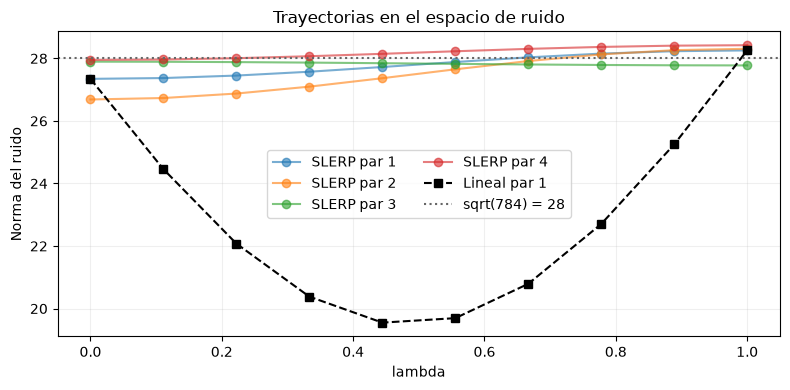

In [20]:
def slerp(z1, z2, lam):
    """Interpole dos vectores de ruido y conserve la forma de sus tensores."""
    if lam == 0:
        return z1.clone()
    if lam == 1:
        return z2.clone()
    a, b = z1.flatten(), z2.flatten()
    na, nb_ = a.norm(), b.norm()
    if na < 1e-8 or nb_ < 1e-8:
        return (1 - lam) * z1 + lam * z2
    u, v = a / na, b / nb_
    cos_theta = torch.dot(u, v).clamp(-1, 1)
    if cos_theta > 1 - 1e-6:
        return (1 - lam) * z1 + lam * z2
    if cos_theta < -1 + 1e-6:
        # Para puntos antipodales, elija un plano de giro determinista.
        base = torch.zeros_like(u)
        base[torch.argmin(u.abs())] = 1
        ortogonal = base - torch.dot(base, u) * u
        ortogonal = ortogonal / ortogonal.norm()
        radio = (1 - lam) * na + lam * nb_
        return (radio * (math.cos(math.pi * lam) * u + math.sin(math.pi * lam) * ortogonal)).view_as(z1)
    theta = torch.acos(cos_theta)
    return (torch.sin((1 - lam) * theta) * z1 + torch.sin(lam * theta) * z2) / torch.sin(theta)

torch.manual_seed(11)
z_comun = torch.randn(4, 1, 28, 28, device=device)
ddim_a = muestrear_ddim(modelo_u, h_lin, z_comun.shape, pasos=50, eta=0, xT=z_comun)
ddim_b = muestrear_ddim(modelo_u, h_lin, z_comun.shape, pasos=50, eta=0, xT=z_comun)
ddpm_a = muestrear_ddpm(modelo_u, h_lin, z_comun.shape, xT=z_comun)
ddpm_b = muestrear_ddpm(modelo_u, h_lin, z_comun.shape, xT=z_comun)
dif_ddim = (ddim_a - ddim_b).abs().max().item()
dif_ddpm = (ddpm_a - ddpm_b).abs().max().item()
assert torch.equal(ddim_a, ddim_b), 'DDIM eta=0 debe repetir la misma salida'
assert dif_ddpm > 0, 'DDPM debe consumir ruido nuevo entre ejecuciones'
print(f'OK  mismo xT: diferencia máxima DDIM = {dif_ddim:.8g}; DDPM = {dif_ddpm:.6f}')

torch.manual_seed(12)
pares = torch.randn(4, 2, 1, 28, 28, device=device)
lambdas = torch.linspace(0, 1, 10).tolist()
ruidos_esfericos = torch.stack([slerp(par[0], par[1], lam) for par in pares for lam in lambdas])
ruidos_lineales = torch.stack([(1 - lam) * pares[0, 0] + lam * pares[0, 1] for lam in lambdas])
normas_esfericas = ruidos_esfericos.flatten(1).norm(dim=1).view(4, 10).cpu()
normas_lineales = ruidos_lineales.flatten(1).norm(dim=1).cpu()
todos_ruidos = torch.cat([ruidos_esfericos, ruidos_lineales])
interpoladas = muestrear_ddim(modelo_u, h_lin, todos_ruidos.shape, pasos=50, eta=0, xT=todos_ruidos)
fig, axes = plt.subplots(5, 1, figsize=(12, 8))
for i in range(5):
    titulo = f'SLERP, par {i + 1}' if i < 4 else 'Lineal, mismo par que la primera fila'
    mostrar(interpoladas[10 * i:10 * (i + 1)], nrow=10, ax=axes[i], titulo=titulo)
plt.tight_layout(); plt.show()
print('Normas SLERP (filas = pares; columnas = lambda):')
print(np.round(normas_esfericas.numpy(), 2))
print('Normas lineales, par 1:', np.round(normas_lineales.numpy(), 2))
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(4):
    ax.plot(lambdas, normas_esfericas[i], marker='o', alpha=0.6, label=f'SLERP par {i + 1}')
ax.plot(lambdas, normas_lineales, 's--', color='black', label='Lineal par 1')
ax.axhline(28, ls=':', color='0.4', label='sqrt(784) = 28')
ax.set(xlabel='lambda', ylabel='Norma del ruido', title='Trayectorias en el espacio de ruido')
ax.legend(ncol=2); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()


**Respuesta:**

Con el mismo ruido inicial y sin reiniciar la semilla entre llamadas, DDIM η=0 produjo imágenes
**idénticas**, con diferencia máxima **0**. DDPM produjo diferencia
máxima **1.964846**, porque añade ruido nuevo en los pasos intermedios.
El modelo EMA está en evaluación; no hay dropout activo durante el muestreo.

Las normas SLERP se mantienen entre **26.69 y 28.42**, cerca del radio típico
√784=28. Para el primer par, las normas cerca del punto medio son **27.72 y 27.88**
con SLERP y **19.55 y 19.69** con interpolación lineal. Esta última entra hacia
el interior de la esfera, una región poco típica del ruido gaussiano en alta dimensión.
En la figura, los pares 1, 3 y 4 se oscurecen hasta casi desaparecer; la fila lineal del primer par
lo hace antes que SLERP. Esta es una limitación visible del modelo de cinco épocas: conservar una norma
típica no garantiza calidad semántica. La implementación también trata normas cero,
vectores casi paralelos y antipodales sin dividir por cero.

## Parte 4. Classifier-free guidance (30 min, 5 pts)

### Tarea 4.1 — Etiqueta vacía (0.5 pts)
Implemente `reemplazar_por_vacio(y, p, vacio)`: cada etiqueta se reemplaza por el índice `vacio` (= 10) con probabilidad `p`, de forma independiente. Luego **lance el entrenamiento condicional** (≈4 min).

In [21]:
def reemplazar_por_vacio(y, p, vacio):
    mascara = torch.rand(y.shape, device=y.device) < p
    return torch.where(mascara, torch.full_like(y, vacio), y)

# ---- prueba
y = torch.randint(0, 10, (100000,), device=device)
assert torch.equal(reemplazar_por_vacio(y, 0.0, 10), y) and (reemplazar_por_vacio(y, 1.0, 10) == 10).all()
fr = (reemplazar_por_vacio(y, 0.1, 10) == 10).float().mean().item()
assert abs(fr - 0.1) < 0.01, fr
print(f'OK  fracción vacía con p=0.1: {fr:.3f}')

torch.manual_seed(0)
unet_c = UNet(n_clases=10).to(device)
unet_c_ema = entrenar(unet_c, h_lin, EPOCAS, cond=True, p_vacio=0.1)

OK  fracción vacía con p=0.1: 0.099


época 1/5 | L_simple 0.0863 | 10s


época 2/5 | L_simple 0.0516 | 10s


época 3/5 | L_simple 0.0479 | 10s


época 4/5 | L_simple 0.0454 | 10s


época 5/5 | L_simple 0.0433 | 10s


### Tarea 4.2 — El ruido guiado (1 pt)
Implemente la ec. 29: $\tilde{\boldsymbol\epsilon}=(1+w)\,\boldsymbol\epsilon_\theta(\mathbf{x}_t,t,c)-w\,\boldsymbol\epsilon_\theta(\mathbf{x}_t,t,\varnothing)$. Para ahorrar tiempo, evalúe ambos términos en **una sola** llamada a la red concatenando el lote consigo mismo.

In [23]:
def eps_guiado(modelo, x, t, y, w, vacio=10):
    etiquetas = torch.cat([y, torch.full_like(y, vacio)])
    pred = modelo(torch.cat([x, x]), torch.cat([t, t]), y=etiquetas)
    condicional, incondicional = pred.chunk(2)
    return (1 + w) * condicional - w * incondicional

# ---- prueba: w = 0 es el modelo condicional; w = -1 es el incondicional
xx, tt = torch.randn(4, 1, 28, 28, device=device), torch.tensor([10, 200, 500, 900], device=device)
yy = torch.tensor([1, 3, 5, 7], device=device)
with torch.no_grad():
    assert torch.allclose(eps_guiado(unet_c_ema, xx, tt, yy, 0.0), unet_c_ema(xx, tt, y=yy), atol=1e-3)
    assert torch.allclose(eps_guiado(unet_c_ema, xx, tt, yy, -1.0), unet_c_ema(xx, tt, y=torch.full_like(yy, 10)), atol=1e-3)
print('OK')

OK


### Tarea 4.3 — La curva fidelidad–diversidad (2 pts)
Para $w\in\{0,\,0.5,\,1,\,2,\,4,\,8\}$ genere 1000 imágenes (100 de cada clase, en el orden de `y_pedido`) con DDIM ($\eta=0$, 50 pasos) **desde el mismo ruido** y calcule:
* **exactitud de clase**: fracción de muestras que el clasificador auxiliar asigna a la clase pedida (fidelidad);
* **diversidad intra-clase** relativa: `diversidad_por_clase(f, y_pedido) / DIV_REAL`;
* **FID\*** contra `f_reales`.

Grafique las tres métricas contra $w$ y la diversidad contra la exactitud (una curva con los puntos etiquetados por $w$). Muestre una cuadrícula (filas = clases, 8 columnas) para $w=0$, $w=2$ y $w=8$. Copie los valores en la Tabla 2 de las instrucciones.

w=0: exactitud=73.000%, diversidad=0.946, FID*=61.331


C:\Users\USER\AppData\Local\Temp\ipykernel_62872\1294712157.py:36: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  raiz = linalg.sqrtm(s1 @ s2)


w=0.5: exactitud=83.900%, diversidad=0.840, FID*=51.188


w=1: exactitud=88.400%, diversidad=0.779, FID*=54.577


w=2: exactitud=87.700%, diversidad=0.749, FID*=77.217


w=4: exactitud=78.400%, diversidad=0.672, FID*=183.542


w=8: exactitud=56.100%, diversidad=0.560, FID*=355.989



Tabla 2. DDIM eta=0, 50 pasos; mismo ruido; 100 muestras por clase.
    w    Exactitud   Div. relativa         FID*
  0.0      73.000%          0.9456       61.331
  0.5      83.900%          0.8400       51.188
  1.0      88.400%          0.7789       54.577
  2.0      87.700%          0.7491       77.217
  4.0      78.400%          0.6717      183.542
  8.0      56.100%          0.5599      355.989


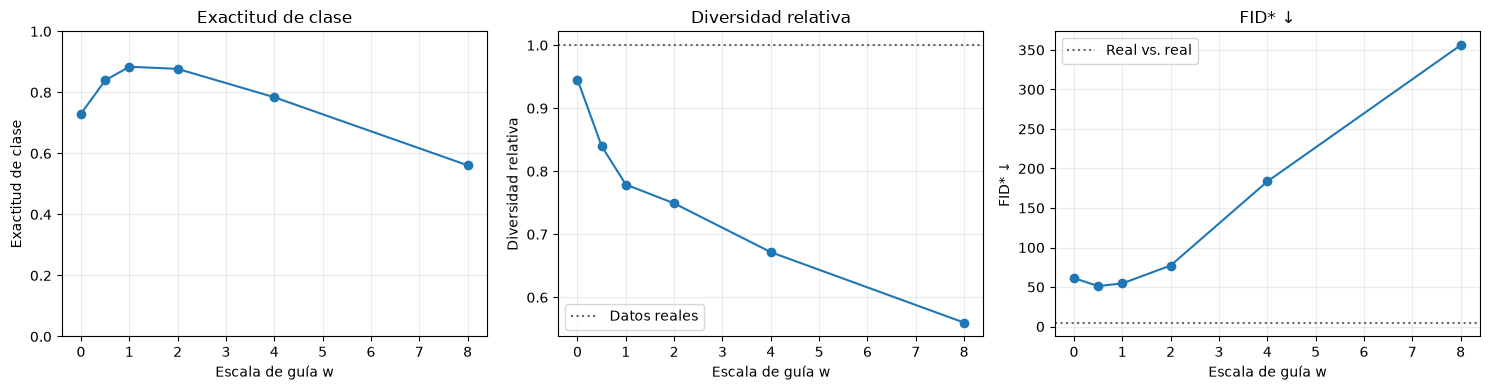

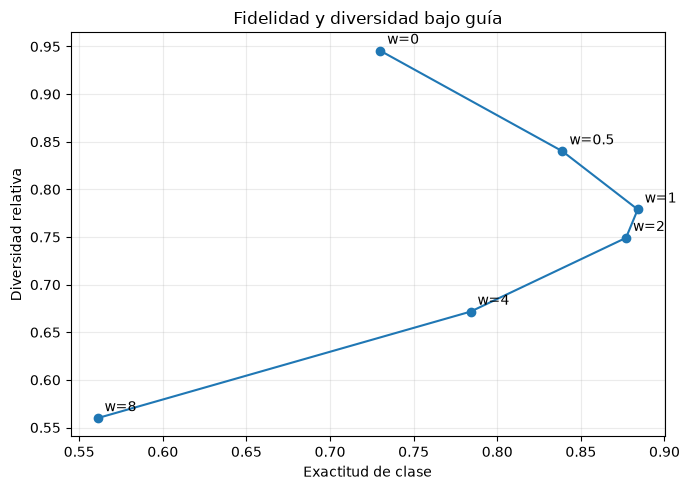

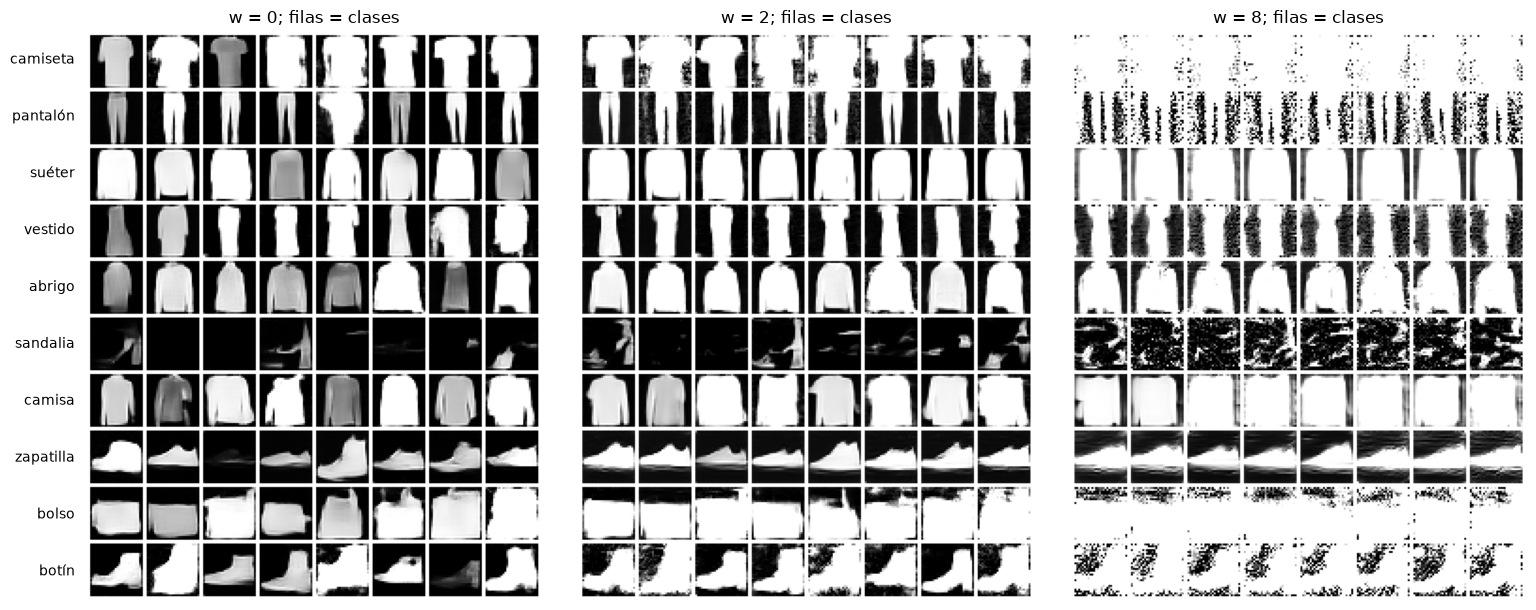

In [24]:
modelo_c = rapido(unet_c_ema)
W = [0.0, 0.5, 1.0, 2.0, 4.0, 8.0]
y_pedido = torch.arange(10).repeat_interleave(N_FID // 10)
torch.manual_seed(7)
xT_fijo = torch.randn(N_FID, 1, 28, 28)
res, ejemplos = [], {}
for w in W:
    partes = []
    for i in range(0, N_FID, 500):
        yb = y_pedido[i:i + 500].to(device)
        zb = xT_fijo[i:i + 500].to(device)
        x = muestrear_ddim(lambda xx, tt: eps_guiado(modelo_c, xx, tt, yb, w),
                           h_lin, zb.shape, pasos=50, eta=0, xT=zb)
        partes.append(x.cpu())
    x = torch.cat(partes)
    f, predichas = caracteristicas(x)
    exactitud = (predichas == y_pedido).float().mean().item()
    diversidad = diversidad_por_clase(f, y_pedido) / DIV_REAL
    valor_fid = fid(f_reales, f)
    res.append((w, exactitud, diversidad, valor_fid))
    ejemplos[w] = torch.cat([x[y_pedido == c][:8] for c in range(10)])
    print(f'w={w:g}: exactitud={exactitud:.3%}, diversidad={diversidad:.3f}, FID*={valor_fid:.3f}', flush=True)

print('\nTabla 2. DDIM eta=0, 50 pasos; mismo ruido; 100 muestras por clase.')
print(f'{"w":>5s} {"Exactitud":>12s} {"Div. relativa":>15s} {"FID*":>12s}')
for w, exactitud, diversidad, valor_fid in res:
    print(f'{w:5.1f} {exactitud:12.3%} {diversidad:15.4f} {valor_fid:12.3f}')

valores = np.asarray(res)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for j, (ax, etiqueta) in enumerate(zip(axes, ['Exactitud de clase', 'Diversidad relativa', 'FID* ↓']), 1):
    ax.plot(valores[:, 0], valores[:, j], 'o-')
    ax.set(xlabel='Escala de guía w', ylabel=etiqueta, title=etiqueta)
    ax.grid(alpha=0.25)
axes[0].set_ylim(0, 1)
axes[1].axhline(1, color='0.4', ls=':', label='Datos reales'); axes[1].legend()
axes[2].axhline(fid_referencia, color='0.4', ls=':', label='Real vs. real'); axes[2].legend()
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(valores[:, 1], valores[:, 2], 'o-')
for w, exactitud, diversidad, _ in res:
    ax.annotate(f'w={w:g}', (exactitud, diversidad), xytext=(5, 5), textcoords='offset points')
ax.set(xlabel='Exactitud de clase', ylabel='Diversidad relativa', title='Fidelidad y diversidad bajo guía')
ax.grid(alpha=0.25); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(16, 7.5))
for ax, w in zip(axes, [0.0, 2.0, 8.0]):
    mostrar(ejemplos[w], nrow=8, ax=ax, titulo=f'w = {w:g}; filas = clases')
for c, nombre in enumerate(CLASES):
    axes[0].text(-0.025, 1 - (c + 0.5) / 10, nombre, transform=axes[0].transAxes,
                 ha='right', va='center', fontsize=10)
plt.subplots_adjust(left=0.09, right=0.99, wspace=0.08); plt.show()


### Tarea 4.4 — Análisis (1.5 pts)
Responda en no más de media página: (a) ¿qué $w$ minimiza el FID\*? ¿Por qué el FID\* empeora para $w$ grande aunque la exactitud siga subiendo? (b) Relacione la curva diversidad–exactitud con el muestreo de $p(\mathbf{x})\,p(c\mid\mathbf{x})^{1+w}$ (notas §8). (c) ¿Qué artefactos ve con $w=8$? ¿Qué pasaría con $p_{\text{vacío}}=0$ en el entrenamiento?

**Respuesta:**

**(a)** El mínimo observado de FID* es **51.188 con w=0.5**;
su exactitud es 83.9% y su diversidad relativa 0.840.
Con w=8, FID*=355.989 y diversidad=0.560. La mayor exactitud fue 88.4% con w=1; con w=8 se obtuvo 56.1%. No se presupone crecimiento monótono.
La exactitud solo mide si el clasificador reconoce la clase solicitada; FID* también responde a
cambios de media y covarianza. Favorecer prototipos reconocibles puede reducir variedad y alejar
las características de las reales.

**(b)** Idealmente, la combinación de scores favorece una densidad proporcional a
$p(x)\,p(c\mid x)^{1+w}$: aumentar w concentra probabilidad en ejemplos más característicos de c.
Esto interpreta el compromiso entre fidelidad y cobertura, sin garantizar tendencias monótonas
con una red aproximada. Se parece al truncamiento del ruido de BigGAN, según
[Ho y Salimans, §3](https://arxiv.org/html/2207.12598v1#S3).

**(c)** Con w=8 aparecen saturación casi blanca en camisetas y bolsos, moteado blanco y negro en pantalones y botines, y pérdida de contornos y detalles. Con p_vacío=0, el embedding vacío no recibiría entrenamiento;
su predicción no sería una estimación incondicional fiable y la extrapolación guiada carecería
de esa referencia. El clasificador auxiliar solo evalúa: no participa en la guía.

## Parte 5. Preguntas de cierre (10 min, 2 pts)

Responda brevemente (3–5 líneas cada una), **usando sus propios números**:
1. Compare el modelo de difusión con la GAN de la Clase 11 en tres ejes: estabilidad del entrenamiento (¿cómo se veían las curvas de pérdida?), cobertura de modos (Tarea 2.3 vs. G4) y costo de generar una imagen (evaluaciones de la red: Tarea 3.2 vs. una pasada de $G$).
2. ¿Por qué pudo usar DDIM (Parte 3) sin reentrenar el modelo entrenado con el Algoritmo 1? Responda con una frase sobre qué depende $L_{\text{simple}}$.
3. Stable Diffusion hace todo esto en un espacio latente de $64\times64\times4$. Con sus tiempos de la Tarea 3.2, estime cuánto más lento sería muestrear directamente en $512\times512\times3$ si el costo de la U-Net creciera proporcionalmente al número de valores.

**Respuesta:**

**1. Difusión frente a GAN.** Las pérdidas por época de la U-Net incondicional fueron
0.0849, 0.0517, 0.0476, 0.0453, 0.0439; las condicionales, 0.0863, 0.0516, 0.0479, 0.0454, 0.0433: descendieron sin divergencia observada.
El MLP cubrió 8/8 modos (98.03% dentro); el PDF describe 1–2 modos
para la GAN de G4, cuya curva no se volvió a ejecutar aquí. DDPM necesita 1000 evaluaciones y
DDIM 50, frente a una pasada del generador GAN; no es una comparación directa de segundos entre redes distintas.

**2. DDIM sin reentrenamiento.** $L_{simple}$ depende de las marginales $q(x_t\mid x_0)$,
del nivel t y de la predicción del ruido; no del acoplamiento temporal que se elija para muestrear.
DDIM conserva esas marginales y reutiliza el predictor entrenado, como explican
[Song, Meng y Ermon](https://arxiv.org/abs/2010.02502).

**3. Espacio latente frente a píxeles.** La razón de valores es
$(512\cdot512\cdot3)/(64\cdot64\cdot4)=\mathbf{48}$.
Con DDIM-50 se midieron 0.97 s/1000 imágenes de 28×28×1. Bajo el escalamiento lineal
supuesto, esto extrapola a **0.020 s** por muestra latente y **0.975 s** en píxeles: 48×.
Son equivalentes de rendimiento por lote, no latencias medidas. Memoria, menor lote y atención espacial
pueden empeorar la práctica; el fundamento del espacio comprimido se presenta en
[Rombach et al.](https://arxiv.org/abs/2112.10752).